<a href="https://colab.research.google.com/github/masterfloss/housing/blob/main/HousingEvolution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Sheet 'Trimestral1_N2024' loaded successfully.


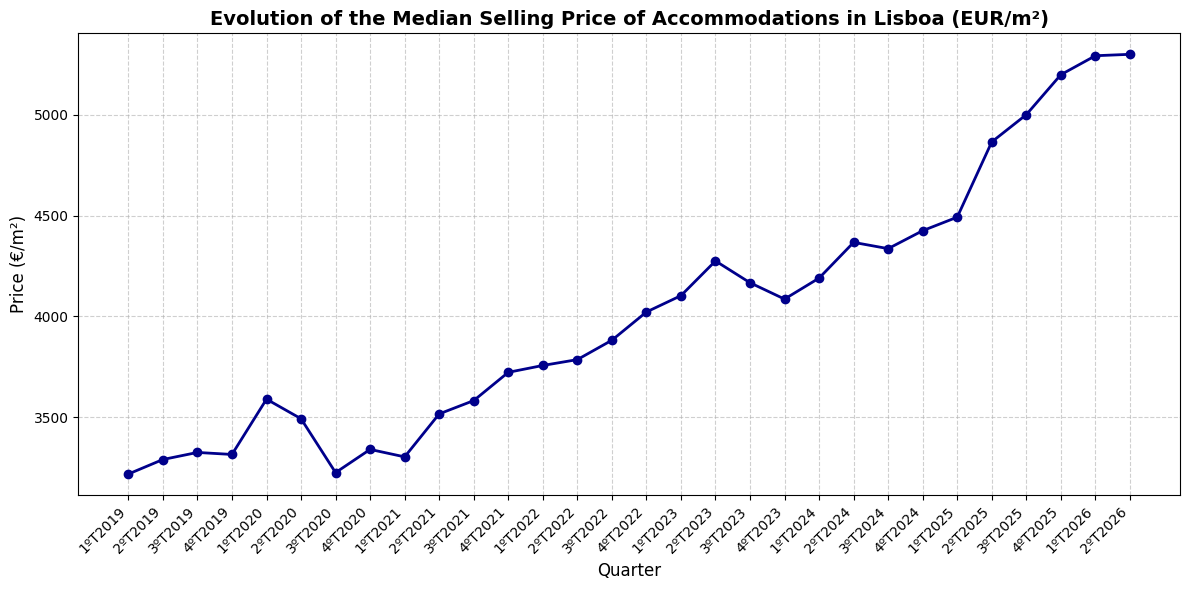

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

class DataReader:
    """Class responsible for reading the housing data from Excel URLs."""
    def __init__(self, url: str):
        self.url = url

    def read_sheet(self, sheet_name: str) -> pd.DataFrame:
        try:
            df = pd.read_excel(self.url, sheet_name=sheet_name)
            print(f"Sheet '{sheet_name}' loaded successfully.")
            return df
        except Exception as e:
            print(f"Error loading Excel file: {e}")
            raise e


class DataCleaner:
    """Class responsible for cleaning and structuring geographical price data."""
    def __init__(self, df_raw: pd.DataFrame):
        self.df_raw = df_raw

    def get_location_series(self, location_name: str) -> pd.DataFrame:
        designacoes = self.df_raw.iloc[:, 1].astype(str).str.strip()
        row_idx = self.df_raw[designacoes.str.lower() == location_name.lower()].index

        if len(row_idx) == 0:
            raise ValueError(f"Location '{location_name}' not found in dataset.")

        idx = row_idx[0]
        quarters = self.df_raw.iloc[1, 2:].values
        prices = self.df_raw.iloc[idx, 2:].values

        series_df = pd.DataFrame({
            'Trimestre': quarters,
            'Preco': prices
        })

        # Filter rows corresponding to quarters (containing 'T')
        series_df = series_df[series_df['Trimestre'].astype(str).str.contains('T', na=False)].copy()

        # Clean price values
        series_df['Preco'] = pd.to_numeric(
            series_df['Preco'].astype(str).str.replace(' ', '').str.replace(',', '.'),
            errors='coerce'
        )
        series_df = series_df.dropna()

        # Keep only the first sequence of unique absolute quarters (before rate of change duplicates begin)
        unique_quarters = []
        unique_prices = []
        for q, p in zip(series_df['Trimestre'], series_df['Preco']):
            q_clean = str(q).strip().replace(' ', '')
            if q_clean not in unique_quarters:
                unique_quarters.append(q_clean)
                unique_prices.append(p)
            else:
                break

        final_df = pd.DataFrame({
            'Trimestre': unique_quarters,
            'Preco': unique_prices
        })

        # Apply chronological sorting
        final_df['sort_key'] = final_df['Trimestre'].apply(self._parse_quarter)
        final_df = final_df.sort_values('sort_key').reset_index(drop=True)
        return final_df[['Trimestre', 'Preco']]

    def _parse_quarter(self, q_str: str) -> tuple:
        match = re.search(r'([1-4])º *T *([0-9]{4})', q_str)
        if match:
            q = int(match.group(1))
            y = int(match.group(2))
            return y, q
        return 0, 0


class DataVisualizer:
    """Class responsible for rendering charts and data tables."""
    @staticmethod
    def plot_price_evolution(df: pd.DataFrame, location_name: str):
        plt.figure(figsize=(12, 6))
        plt.plot(df['Trimestre'], df['Preco'], marker='o', color='darkblue', linewidth=2)
        plt.title(f'Evolution of the Median Selling Price of Accommodations in {location_name} (EUR/m²)', fontsize=14, fontweight='bold')
        plt.xlabel('Quarter', fontsize=12)
        plt.ylabel('Price (€/m²)', fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(True, linestyle='--', alpha=0.6)
        plt.tight_layout()
        plt.show()

        #display(df)


# Execution Flow
if __name__ == "__main__":
    url = "https://github.com/masterfloss/housing/raw/refs/heads/main/Destaque_HAB_2T2026_PT.xlsx"
    sheet_name = "Trimestral1_N2024"

    # 1. Read Data
    reader = DataReader(url)
    df_raw = reader.read_sheet(sheet_name)

    # 2. Clean Data
    cleaner = DataCleaner(df_raw)
    lisbon_df = cleaner.get_location_series("Lisboa")

    # 3. Visualize Data
    visualizer = DataVisualizer()
    visualizer.plot_price_evolution(lisbon_df, "Lisboa")
